# 基于技术指标的股票次日涨跌概率预测

### 项目成员及分工
| 项目成员 | 学号 | 
|---|---|
| 胡迪 | 2023301051013 |

## 选题背景

本项目以行业月度超额收益为研究对象，使用 Lasso 回归从多类候选变量中筛选对不同行业收益有解释力的因子，并考察模型在留出的后期样本上的表现。

## 运行环境说明
### 运行环境

运行前请将 `tidy_finance.sqlite` 放在 Notebook 的工作目录，并安装 `polars`、`numpy`、`scikit-learn` 和 `matplotlib`。

### 所用模型说明

模型采用 Lasso 线性回归。L1 惩罚会将部分变量系数压缩为零，从而实现变量筛选；建模时使用 `StandardScaler` 标准化特征，并用滚动验证选择惩罚参数 `alpha`。


## 数据集说明及处理
### 数据集来源

建模使用的是 `tidy_finance.sqlite` 里的四张月度表。因子和宏观变量的原始来源如下。

#### Fama-French Data（Ken French）

FF 因子从 Kenneth French 数据库下载：http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html

可以通过 `pandas_datareader.famafrench` 查看其中的数据表。本项目使用其中的三因子月度数据，以及 10 个行业组合的月收益率。

#### q 因子

q 因子直接从作者 Hou、Xue 与 Zhang（2014）的公开数据下载：https://global-q.org/uploads/1/2/2/6/122679606/q5_factors_monthly_2022.csv

其中包含市场超额收益率 `mkt`、规模因子 `me`、投资因子 `ia`、盈利因子 `roe` 和增长因子 `eg`。

#### 宏观数据

宏观预测变量来自经管院订购的数据。读入后删除 `rp_div`，其余宏观变量与因子一起进入候选集。

### 数据集划分

对每个行业按日期排序，将前 80% 的观测作为训练期，后 20% 作为测试期。训练期内部如何滚动验证，见下方第 3 节。

### 数据预处理

从 SQLite 中读取 Fama-French 三因子、q 因子、宏观预测变量和行业收益四张月度表。行业收益宽表先转换为长表，再按日期与因子、宏观变量合并；以行业收益减去同期无风险收益得到超额收益。候选变量包括原始因子、宏观变量及其交互项，并删除含非有限数值的样本。


## 模型与优化过程

### Lasso 模型构建

对每个行业分别建立 Lasso 线性回归模型，以行业当月超额收益为目标变量：

$$
y_{i,t}=r_{i,t}-r_{f,t},\qquad
y_{i,t}=b_i+\sum_{j=1}^{p}\beta_{i,j}z_{t,j}+\varepsilon_{i,t}.
$$

其中，$i$ 表示行业，$t$ 表示月份，$r_{i,t}$ 为行业收益，$r_{f,t}$ 为同期无风险收益，$b_i$ 为截距，$\beta_{i,j}$ 为第 $j$ 个候选变量的系数，$\varepsilon_{i,t}$ 为误差项。候选变量包括原始因子、宏观变量及“宏观变量 × 因子”交互项，当前输出共包含 $p=153$ 个候选变量。特征和收益按同月匹配，因此该模型用于行业超额收益的同月拟合与因子筛选。

交互项在标准化前构造。对每次拟合所用的训练样本集合 $T$，使用 `StandardScaler` 将各列转换为

$$
z_{t,j}=\frac{x_{t,j}-\mu_{T,j}}{s_{T,j}},
$$

其中 $\mu_{T,j}$ 和 $s_{T,j}$ 分别为该列在训练样本上的均值与标准差；常数列按 `StandardScaler` 的规则处理。验证集和测试集沿用相应训练集的转换参数。每个验证折先独立拟合标准化器，再训练 Lasso；相同折的候选参数共用该折的转换结果。最终将完整训练期的标准化器与已拟合的 Lasso 组合为 Pipeline，供测试期预测使用。

### 目标函数与求解方法

对行业 $i$，在包含 $n$ 条观测的训练样本上求解：

$$
(\hat b_i,\hat{\boldsymbol\beta}_i)
=\arg\min_{b_i,\boldsymbol\beta_i}
\left\{
\frac{1}{2n}\sum_{t\in T}
\left(y_{i,t}-b_i-\sum_{j=1}^{p}\beta_{i,j}z_{t,j}\right)^2
+\alpha\sum_{j=1}^{p}|\beta_{i,j}|
\right\}.
$$

第一项是平方误差损失，第二项是 L1 正则化惩罚，截距不参与惩罚。$\alpha$ 对应代码中的 `alpha`：较小的值允许模型保留更多变量，较大的值会加强系数收缩，并可能将全部系数压为零。标准化使不同量纲的候选变量在统一尺度上受到惩罚。

`Lasso` 采用坐标下降法求解，每次更新一个系数，其余系数保持不变。令 $u_{t,j}=y_{i,t}-b_i-\sum_{k\ne j}\beta_{i,k}z_{t,k}$ 为去掉第 $j$ 项后的残差，则非恒定列的更新可写为

$$
\beta_{i,j}\leftarrow
\frac{S\!\left(\frac{1}{n}\sum_{t\in T}z_{t,j}u_{t,j},\alpha\right)}
{\frac{1}{n}\sum_{t\in T}z_{t,j}^{2}},
\qquad S(a,\alpha)=\operatorname{sign}(a)\max(|a|-\alpha,0).
$$

软阈值函数 $S$ 将绝对值不超过阈值的更新压为零，从而实现变量筛选。优化后的代码仍采用坐标下降法，固定 `tol=1e-4`，没有通过放宽精度消除收敛警告。

### 方法优化：扩展窗口验证与 one-SE 选参

上一版主要改进计算效率和求解收敛。本版进一步调整验证方式与参数选择规则，目标是在误差可接受的范围内得到更简约的行业因子组合，并检查入选结果是否随训练月份变化。

**1. 扩展窗口验证。** 每个行业仍按时间将前 80% 留作训练期、后 20% 留作测试期。原固定窗口每折只训练 60 个月，而最终拟合使用完整的 536 个月；原窗口步长还使末尾 44 个训练月份未进入验证。本版使用 `TimeSeriesSplit(n_splits=5, test_size=48)`，五折训练月数依次为 296、344、392、440、488，每折验证随后 48 个月，最后一折覆盖到训练期末尾。训练期逐步扩展，更接近最终利用全部历史样本拟合的方式。该选择保留了长期历史，若关系存在结构突变，也可能不如较短窗口适应得快。

**2. one-SE 简约选参。** 不再只追求验证 MSE 的最低点。首先在所有完整训练期非零系数不超过 5 个、且全部拟合收敛的候选中找到最小平均验证误差；再选取误差处于“最小值加一个标准误”范围内的最大 $\alpha$，施加更强正则化。

令第 $k$ 折验证 MSE 为 $E_k(\alpha)$，则

$$
\bar E(\alpha)=\frac{1}{K}\sum_{k=1}^{K}E_k(\alpha),\qquad
\operatorname{SE}(\alpha)=\frac{s(E_1(\alpha),\ldots,E_K(\alpha))}{\sqrt K},
$$

$$
\alpha_{\min}=\arg\min_{\alpha\in\mathcal A}\bar E(\alpha),\qquad
\alpha_{\mathrm{1SE}}=\max\left\{\alpha\in\mathcal A:
\bar E(\alpha)\leq\bar E(\alpha_{\min})+\operatorname{SE}(\alpha_{\min})\right\}.
$$

$\mathcal A$ 是满足收敛条件和完整训练期变量上限的候选集合，$s$ 使用样本标准差。这里的标准误按五个时间折计算；由于时间依赖和训练窗口重叠，one-SE 仅作为经验简约规则，不能将这个范围解释为正式置信区间。更强惩罚可能增加拟合偏差，也不保证测试误差降低。

代码默认 `SELECTION_RULE="one_se"`，适用于本作业的因子筛选目标。`min_mse` 保留为同一验证方案下的对照选参规则；若调整该配置，应由建模目标决定，不能反复查看测试结果后挑选更好看的版本。汇总表同时报告两种规则的参数与验证误差，但最终测试评价只使用预先选定规则产生的模型。

**3. 跨窗口因子稳定性诊断。** 固定最终选定的 $\alpha$，统计每个变量在五个训练窗口中系数非零的比例，以及非零系数与最终完整训练期系数同号的比例。例如，入选频率为 0.8 表示五折中有四折选中该变量，不表示它有 80% 的概率是真实因子。另报告不同窗口入选集合两两之间的平均 Jaccard 相似度；两个集合均为空时记为 1。诊断不会再次删除变量或使用测试数据重新选参，也不属于带有错误选择率保证的正式稳定性选择方法。

训练期中两套市场因子的相关系数约为 0.99997，相关变量可能互相替代。因此，“保留了市场暴露”与“某一具体列始终入选”需要区别解释，较少的变量也不自动等于稳定的因子集合。另将两套市场因子以及相同宏观变量与它们构成的交互项分别视为同类暴露组，统计任一成员入选的跨折频率。这个分组只用于结果解释，不合并输入、不更改系数、不参与选参；组稳定也不证明某一具体列具有独立解释力。

### 训练和求解设置

| 环节 | 设置与记录 |
|---|---|
| 外层样本划分 | 按日期前 80% 训练、后 20% 测试，月份必须连续且不重复 |
| 扩展验证 | 5 折，每折验证 48 个月，初始训练期至少 120 个月 |
| 标准化 | 完整训练期与各验证折分别拟合；每折只使用本折训练数据计算均值和标准差 |
| 粗搜 | $10^{-5}$ 至 $1$ 的 40 个对数等距 $\alpha$ |
| 细搜 | 分别在粗搜最小误差参数与 one-SE 参数的相邻网格区间内取 17 点，跳过重复参数 |
| 变量数量 | 完整训练期最多 5 个非零系数，不限制各验证折的入选数；允许截距模型 |
| 最终参数 | 默认 one-SE；同时保留最小验证误差规则的对照记录 |
| 数值求解 | 相同数据上从大到小遍历 $\alpha$ 并热启动，不跨验证折共享系数 |
| 收敛处理 | `tol=1e-4`，迭代上限按 5,000、50,000、200,000 递增重试，不放宽容差 |

变量上限仍是在完整训练期拟合后的规则，不是目标函数中的额外约束。它与参数选择均属于训练期内部建模步骤，验证误差用于调参，不作为独立的样本外证据。后期测试数据没有传入训练函数，也不用于标准化、粗搜、细搜或 one-SE 阈值计算。由于这段历史测试期在开发中已被多次查看，进一步确认泛化能力仍需要未使用的新数据。

### 优化过程记录

第 4 节自动在 `lasso_method_results` 文件夹保存本版结果：

| 文件 / 表 | 记录内容 |
|---|---|
| `优化汇总.csv` / `lasso_optimization` | 最小误差与 one-SE 参数、对应验证误差、one-SE 阈值、最终入选数、入选集合相似度、重试次数和耗时 |
| `参数搜索记录.csv` / `lasso_search_log` | 每个参数的阶段、收敛情况、完整训练期入选数、平均验证 MSE、跨折标准误和排除原因 |
| `求解日志.csv` / `lasso_fit_log` | 每次拟合或重试的行业、样本窗口、参数、迭代数、对偶间隙、目标函数、耗时及警告原文 |
| `因子稳定性.csv` / `lasso_stability` | 完整训练期系数、是否最终入选、验证折入选次数和频率、与最终系数的符号一致率 |
| `因子组稳定性.csv` / `lasso_group_stability` | 区分同类市场因子之间的替代与整个暴露组的消失，报告成员及组入选频率 |
| `分折验证记录.csv` / `lasso_fold_metrics` | 各折训练与验证月份、训练长度、两种选参规则的分折 MSE、最终模型分折入选数 |

目标函数值记录在每次拟合尝试结束时，并非每次坐标更新的轨迹。对偶间隙检查阈值为 `tol × mean((y - mean(y))²)`，同时要求没有收敛警告。最终仍未收敛的候选被排除，数量写入汇总。

原来的 `lasso_results` 保存上一轮计算效率优化的历史记录，不能与本版扩展窗口验证的 MSE 直接比较；两版使用的验证月份和训练长度不同。方法对照与具体结果见本版输出及随包提供的说明。

### 评估与结果解释

测试集仍报告 MSE、RMSE 和相对训练期均值预测的样本外 $R^2$；原第 6 节市场回归对照代码保持不变。后续图表继续读取同名结果表。原第 5 至 7 节的静态分析文字按原范围保留，其中历史数值需与新输出核对。

方法参考：[TimeSeriesSplit 官方文档](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)、[glmnet 作者关于 one-SE 的说明](https://cran.stat.auckland.ac.nz/web/packages/glmnet/vignettes/glmnet.pdf)、[scikit-learn 关于相关变量下 Lasso 筛选的示例](https://scikit-learn.org/stable/auto_examples/linear_model/plot_lasso_and_elasticnet.html)。


# 4.1 用 Lasso 筛选行业因子

用 Lasso 为每个行业筛选最多五个变量，用最后 20% 的月份检验模型的样本外表现。

运行前将 `tidy_finance.sqlite` 放在 Notebook 的工作目录，安装 `polars`、`numpy`、`scikit-learn` 和 `matplotlib`。

## 1. 读取和合并月度数据

用 Polars 直接读取四张 SQLite 表。行业宽表转成长表后，每行是一个行业的一个月，目标变量是行业收益减当月无风险收益。

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

db_path = Path("tidy_finance.sqlite")
if not db_path.is_file():
    raise FileNotFoundError(f"请将 tidy_finance.sqlite 放到 {db_path.resolve().parent}")


def read_monthly(conn, table, prefix=""):
    frame = pl.read_database(
        f'SELECT * FROM "{table}"',
        conn,
        schema_overrides={"date": pl.String},
        infer_schema_length=None,
    )
    return (
        frame.drop("__index_level_0__", strict=False)
        .with_columns(pl.col("date").str.slice(0, 10).str.to_date("%Y-%m-%d"))
        .rename(lambda name: name if name == "date" else f"{prefix}{name}")
    )


with closing(sqlite3.connect(db_path)) as conn:
    ff = read_monthly(conn, "factors_ff3_monthly", "factor_ff_")
    q = read_monthly(conn, "factors_q_monthly", "factor_q_")
    macro = read_monthly(conn, "macro_predictors", "macro_").drop("macro_rp_div")
    returns = read_monthly(conn, "industries_ff_monthly").unpivot(
        index="date", variable_name="industry", value_name="ret"
    )

data = (
    returns.join(ff, on="date", how="inner", validate="m:1")
    .join(q, on="date", how="inner", validate="m:1")
    .join(macro, on="date", how="inner", validate="m:1")
    .with_columns(ret_excess=pl.col("ret") - pl.col("factor_ff_rf"))
    .drop("ret", "factor_ff_rf")
)

## 2. 构造候选变量

原始因子、宏观变量及其交互项都进入候选集。交互项让因子的回归斜率随宏观环境变化。无风险收益只用于定义超额收益。

In [2]:
factor_cols = [name for name in data.columns if name.startswith("factor_")]
macro_cols = [name for name in data.columns if name.startswith("macro_")]
interactions = [
    (pl.col(macro_name) * pl.col(factor_name)).alias(f"{macro_name} × {factor_name}")
    for macro_name in macro_cols
    for factor_name in factor_cols
]
data = data.with_columns(interactions)
feature_cols = [name for name in data.columns if name not in {"date", "industry", "ret_excess"}]
numeric_cols = [*feature_cols, "ret_excess"]
data = data.filter(pl.all_horizontal(pl.col(numeric_cols).is_finite())).sort(
    ["industry", "date"]
)
print(f"{data.height:,} 条行业月度样本，{len(feature_cols)} 个候选变量")
display(data.select("date", "industry", "ret_excess", *factor_cols[:3]).head())

6,710 条行业月度样本，153 个候选变量


date,industry,ret_excess,factor_ff_mkt_excess,factor_ff_smb,factor_ff_hml
date,str,f64,f64,f64,f64
1967-01-01,"""durbl""",0.1135,0.0815,0.0823,0.0222
1967-02-01,"""durbl""",-0.0145,0.0077,0.0333,-0.0225
1967-03-01,"""durbl""",0.0345,0.0399,0.0154,0.0041
1967-04-01,"""durbl""",0.1074,0.0389,0.0043,-0.0227
1967-05-01,"""durbl""",-0.0768,-0.0432,0.0209,0.0084


## 3. 用扩展窗口验证与 one-SE 规则选择 Lasso

按日期将前 80% 观测用于训练与调参，后 20% 留作测试。训练期内部使用 5 个扩展窗口，每折验证 48 个月，最后一折覆盖训练期末尾；标准化仅在各折训练样本上拟合。

先粗搜，再细化最小验证误差点与 one-SE 点附近的参数。最终默认选择平均验证 MSE 不超过“最小值加一个标准误”的最大 alpha，同时要求完整训练期非零系数不超过 5 个、全部拟合收敛。固定最终参数后，报告各因子的跨窗口入选频率和符号一致性。这些诊断不使用测试数据，也不作为显著性或因果判断。


In [3]:
import warnings
from copy import deepcopy
from time import perf_counter

from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import TimeSeriesSplit

MAX_FACTORS = 5
ALPHAS = np.logspace(-5, 0, 40)
FINE_POINTS = 17
MIN_TRAIN_MONTHS, VALID_WINDOW, N_SPLITS = 120, 48, 5
SELECTION_RULE = "one_se"  # 因子筛选；若目标明确为验证误差最小，可改为 "min_mse"。
LASSO_TOL = 1e-4
ITERATION_BUDGETS = (5_000, 50_000, 200_000)
lasso_runs = {}


def industry_sample(industry):
    frame = data.filter(pl.col("industry") == industry).sort("date")
    months = np.array(frame["date"].to_list(), dtype="datetime64[M]").astype(int)
    if len(months) < 2 or not np.all(np.diff(months) == 1):
        raise ValueError(f"{industry} 的月份存在重复、间断或样本不足")
    split = int(frame.height * 0.8)
    if split < MIN_TRAIN_MONTHS + N_SPLITS * VALID_WINDOW:
        raise ValueError(f"{industry} 的训练期不足以构造 {N_SPLITS} 个扩展验证窗口")
    folds = list(TimeSeriesSplit(n_splits=N_SPLITS, test_size=VALID_WINDOW).split(np.arange(split)))
    return frame.select(feature_cols).to_numpy(), frame["ret_excess"].to_numpy(), split, folds


def fit_sparse_lasso(x_train, y_train, folds):
    """仅接收训练期数据；扩展窗口验证、局部细搜与 one-SE 简约选参。"""
    started = perf_counter()
    fit_rows, search_rows = [], []
    candidate_models, fold_coefficients, fold_errors = {}, {}, {}
    x_train = np.asarray(x_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    if not np.isfinite(x_train).all() or not np.isfinite(y_train).all():
        raise ValueError("Lasso 训练样本存在非有限值")
    if len(folds) < 2:
        raise ValueError("至少需要两个时间验证折，以计算跨折误差标准误")
    if SELECTION_RULE not in {"min_mse", "one_se"}:
        raise ValueError("SELECTION_RULE 只能为 min_mse 或 one_se")

    scaler = StandardScaler().fit(x_train)
    z_full = np.asfortranarray(scaler.transform(x_train))
    fold_data = []
    for train, valid in folds:
        if (len(train) == 0 or len(valid) == 0 or min(train) < 0
                or max(train) >= min(valid) or max(valid) >= len(y_train)):
            raise ValueError("验证折必须位于训练期内部，且训练月份严格早于验证月份")
        fold_scaler = StandardScaler().fit(x_train[train])
        fold_data.append((
            np.asfortranarray(fold_scaler.transform(x_train[train])), y_train[train],
            fold_scaler.transform(x_train[valid]), y_train[valid],
        ))

    def new_lasso():
        return Lasso(tol=LASSO_TOL, warm_start=True, selection="cyclic")

    def fit_checked(estimator, z, y, stage, fold):
        # 每次重试沿用同一数据、同一 alpha 的系数，不放宽 tol。
        gap_limit = LASSO_TOL * float(np.mean((y - y.mean()) ** 2))
        for attempt, budget in enumerate(ITERATION_BUDGETS, 1):
            estimator.set_params(max_iter=budget)
            tic = perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                estimator.fit(z, y)
            convergence_messages = [str(w.message) for w in caught
                                    if issubclass(w.category, ConvergenceWarning)]
            for warning in caught:
                if not issubclass(warning.category, ConvergenceWarning):
                    warnings.warn(str(warning.message), warning.category)
            gap = float(estimator.dual_gap_)
            converged = (not convergence_messages and np.isfinite(gap)
                         and gap <= gap_limit + 10 * np.finfo(float).eps)
            loss = mean_squared_error(y, estimator.predict(z)) / 2
            fit_rows.append({
                "阶段": stage, "拟合样本": fold, "alpha": float(estimator.alpha),
                "尝试次数": attempt, "本次迭代上限": budget,
                "实际迭代数": int(estimator.n_iter_), "dual_gap": gap,
                "收敛阈值": gap_limit, "已收敛": bool(converged),
                "入选数": int(np.count_nonzero(estimator.coef_)),
                "目标函数": float(loss + estimator.alpha * np.abs(estimator.coef_).sum()),
                "耗时（秒）": perf_counter() - tic,
                "收敛警告": " | ".join(convergence_messages),
            })
            if converged:
                return True
        return False

    def search_stage(alphas, stage):
        rows, models = {}, {}
        path_model = new_lasso()
        # 由强到弱沿正则化路径热启动；每个模型的系数单独保存。
        for alpha in sorted(set(map(float, alphas)), reverse=True):
            path_model.set_params(alpha=alpha)
            ok = fit_checked(path_model, z_full, y_train, stage, "完整训练期")
            count = int(np.count_nonzero(path_model.coef_))
            rows[alpha] = {
                "阶段": stage, "alpha": alpha, "完整训练期已收敛": ok,
                "入选数": count, "验证收敛折数": 0, "验证MSE": None, "验证MSE标准误": None,
                "候选状态": "待验证" if ok and count <= MAX_FACTORS else
                             ("超过变量上限" if ok else "完整训练期未收敛"),
            }
            if ok and count <= MAX_FACTORS:
                models[alpha] = deepcopy(path_model)

        mse_by_alpha = {alpha: [] for alpha in models}
        coef_by_alpha = {alpha: [] for alpha in models}
        for fold, (z, y, z_valid, y_valid) in enumerate(fold_data, 1):
            path_model = new_lasso()  # 不跨验证折共享系数或标准化参数。
            for alpha in sorted(models, reverse=True):
                path_model.set_params(alpha=alpha)
                if fit_checked(path_model, z, y, stage, f"验证折{fold}"):
                    mse_by_alpha[alpha].append(mean_squared_error(y_valid, path_model.predict(z_valid)))
                    coef_by_alpha[alpha].append(path_model.coef_.copy())
        for alpha, errors in mse_by_alpha.items():
            rows[alpha]["验证收敛折数"] = len(errors)
            if len(errors) == len(fold_data):
                rows[alpha].update({
                    "验证MSE": float(np.mean(errors)),
                    "验证MSE标准误": float(np.std(errors, ddof=1) / np.sqrt(len(errors))),
                    "候选状态": "可选",
                })
                candidate_models[alpha] = models[alpha]
                fold_coefficients[alpha] = np.array(coef_by_alpha[alpha])
                fold_errors[alpha] = errors
            else:
                rows[alpha]["候选状态"] = "存在未收敛验证折"
        search_rows.extend(rows.values())
        eligible = [row for row in rows.values() if row["候选状态"] == "可选"]
        if not eligible:
            return None
        best = min(eligible, key=lambda row: (row["验证MSE"], row["alpha"]))
        return best, models[best["alpha"]]

    coarse = search_stage(ALPHAS, "粗搜")
    if coarse is None:
        raise ValueError("没有收敛且满足变量上限的候选；请检查求解日志或扩大 alpha 范围。")
    def select_candidates():
        eligible = [row for row in search_rows if row["候选状态"] == "可选"]
        minimum = min(eligible, key=lambda row: (row["验证MSE"], row["alpha"]))
        threshold = minimum["验证MSE"] + minimum["验证MSE标准误"]
        # one-SE 是时间折上的经验简约规则，不将该阈值解释为置信区间。
        simpler = max((row for row in eligible if row["验证MSE"] <= threshold),
                      key=lambda row: row["alpha"])
        return minimum, simpler, threshold

    coarse_min, coarse_one_se, _ = select_candidates()
    fine_alphas = []
    # 同时细化最小误差点与 one-SE 点附近，避免只细化一种选择规则。
    for center in {coarse_min["alpha"], coarse_one_se["alpha"]}:
        position = int(np.argmin(np.abs(ALPHAS - center)))
        lower = ALPHAS[max(0, position - 1)]
        upper = ALPHAS[min(len(ALPHAS) - 1, position + 1)]
        fine_alphas.extend(a for a in np.geomspace(lower, upper, FINE_POINTS)
                           if not np.any(np.isclose(a, ALPHAS, rtol=1e-12, atol=0)))
    if fine_alphas:
        search_stage(fine_alphas, "细搜")
    minimum, simpler, threshold = select_candidates()
    selected = simpler if SELECTION_RULE == "one_se" else minimum
    best = selected, candidate_models[selected["alpha"]]
    chosen_coefs = fold_coefficients[selected["alpha"]]
    support = chosen_coefs != 0
    full_coefs = best[1].coef_
    stability_rows = []
    for j in range(x_train.shape[1]):
        count = int(support[:, j].sum())
        if count == 0 and full_coefs[j] == 0:
            continue
        aligned = int(np.sum((np.sign(chosen_coefs[:, j]) == np.sign(full_coefs[j])) & support[:, j]))
        stability_rows.append({
            "特征序号": j, "最终入选": bool(full_coefs[j] != 0),
            "完整训练系数（百分点）": 100 * float(full_coefs[j]),
            "验证折入选次数": count, "验证折数": len(folds),
            "入选频率": count / len(folds),
            "与最终符号一致率": aligned / count if count and full_coefs[j] != 0 else None,
        })
    overlaps = []
    for i in range(len(folds)):
        for j in range(i):
            union = np.count_nonzero(support[i] | support[j])
            overlaps.append(np.count_nonzero(support[i] & support[j]) / union if union else 1.0)
    model = make_pipeline(scaler, best[1])  # 两步均已拟合，不再重复训练。
    summary = {
        "选择规则": SELECTION_RULE,
        "最小误差alpha": minimum["alpha"], "oneSEalpha": simpler["alpha"],
        "最小误差入选数": minimum["入选数"], "oneSE入选数": simpler["入选数"],
        "最小误差因子平均入选频率": float((fold_coefficients[minimum["alpha"]][:, candidate_models[minimum["alpha"]].coef_ != 0] != 0).mean()) if minimum["入选数"] else None,
        "最小误差验证RMSE（百分点）": 100 * np.sqrt(minimum["验证MSE"]),
        "oneSE验证RMSE（百分点）": 100 * np.sqrt(simpler["验证MSE"]),
        "oneSE阈值MSE": threshold,
        "粗搜alpha": coarse[0]["alpha"], "最终alpha": best[0]["alpha"],
        "粗搜验证RMSE（百分点）": 100 * np.sqrt(coarse[0]["验证MSE"]),
        "最终验证RMSE（百分点）": 100 * np.sqrt(best[0]["验证MSE"]),
        "粗搜入选数": coarse[0]["入选数"], "最终入选数": best[0]["入选数"],
        "候选数": len(search_rows), "拟合尝试数": len(fit_rows),
        "重试次数": sum(row["尝试次数"] > 1 for row in fit_rows),
        "未收敛排除候选数": sum("未收敛" in row["候选状态"] for row in search_rows),
        "平均支持集Jaccard": float(np.mean(overlaps)),
        "最终因子平均入选频率": float(support[:, full_coefs != 0].mean()) if np.any(full_coefs != 0) else None,
        "训练调参耗时（秒）": perf_counter() - started,
    }
    return model, float(np.sqrt(best[0]["验证MSE"])), {
        "搜索记录": search_rows, "求解日志": fit_rows, "优化汇总": summary,
        "因子稳定性": stability_rows, "_fold_coef": chosen_coefs,
        "分折验证": [{"验证折": k + 1, "训练月数": len(train), "验证月数": len(valid),
                      "训练末月序号": int(max(train)), "验证首月序号": int(min(valid)),
                      "验证末月序号": int(max(valid)),
                      "最小误差模型MSE": fold_errors[minimum["alpha"]][k],
                      "oneSE模型MSE": fold_errors[simpler["alpha"]][k],
                      "最终模型MSE": fold_errors[selected["alpha"]][k],
                      "最终模型入选数": int(support[k].sum())}
                     for k, (train, valid) in enumerate(folds)],
    }


def evaluate(industry):
    x, y, split, folds = industry_sample(industry)
    model, validation_rmse, records = fit_sparse_lasso(x[:split], y[:split], folds)
    frame_dates = data.filter(pl.col("industry") == industry).sort("date")["date"].to_list()
    for row in records["因子稳定性"]:
        row["变量"] = feature_cols[row.pop("特征序号")]
    for row in records["分折验证"]:
        for key in ["训练末月序号", "验证首月序号", "验证末月序号"]:
            row[key.replace("序号", "日期")] = str(frame_dates[row.pop(key)])
    # 市场因子及相同宏观变量的市场交互项按同类暴露分组；不改变模型或系数。
    fold_support = records.pop("_fold_coef") != 0
    full_support = model.named_steps["lasso"].coef_ != 0
    groups = {}
    for j, name in enumerate(feature_cols):
        group = name.replace("factor_ff_mkt_excess", "市场因子（FF/q）").replace("factor_q_mkt", "市场因子（FF/q）")
        groups.setdefault(group, []).append(j)
    group_rows = []
    for group, columns in groups.items():
        chosen = [feature_cols[j] for j in columns if full_support[j]]
        count = int(np.any(fold_support[:, columns], axis=1).sum())
        if count == 0 and not chosen:
            continue
        group_rows.append({
            "因子组": group, "成员": "；".join(feature_cols[j] for j in columns),
            "最终入选成员": "；".join(chosen), "最终组入选": bool(chosen),
            "验证折入选次数": count, "验证折数": len(folds), "组入选频率": count / len(folds),
        })
    records["因子组稳定性"] = group_rows
    selected_group_rates = [r["组入选频率"] for r in group_rows if r["最终组入选"]]
    records["优化汇总"]["最终因子组平均入选频率"] = float(np.mean(selected_group_rates)) if selected_group_rates else None
    lasso_runs[industry] = records
    pred = model.predict(x[split:])
    test_mse = mean_squared_error(y[split:], pred)
    baseline_mse = mean_squared_error(y[split:], np.full_like(y[split:], y[:split].mean()))
    lasso = model.named_steps["lasso"]
    metrics = {
        "行业": industry, "alpha": lasso.alpha,
        "验证 RMSE（百分点）": 100 * validation_rmse,
        "测试 RMSE（百分点）": 100 * np.sqrt(test_mse),
        "基准 RMSE（百分点）": 100 * np.sqrt(baseline_mse),
        "样本外 R²": 1 - test_mse / baseline_mse if baseline_mse > 0 else None,
    }
    return lasso.coef_, metrics


## 4. 查看各行业的入选变量、测试表现与稳定性

结果表和热图展示最终 one-SE Lasso 模型。优化汇总同时报告最小误差规则和 one-SE 规则的验证结果；稳定性表展示最终入选变量在五个训练窗口中的出现频率与符号一致性。各类记录自动保存到 `lasso_method_results`，RMSE 和系数以百分点报告。


In [4]:
coefficient_rows, metric_rows = [], []
industries = data["industry"].unique().sort().to_list()

for industry in industries:
    coef, metrics = evaluate(industry)

    selected = coef != 0
    metric_rows.append({**metrics, "入选数": int(selected.sum())})
    coefficient_rows.extend(
        {"行业": industry, "变量": name, "系数（百分点）": 100 * float(weight)}
        for name, weight, keep in zip(feature_cols, coef, selected)
        if keep
    )

industry_metrics = pl.DataFrame(metric_rows)
selected_factors = pl.DataFrame(
    coefficient_rows,
    schema={"行业": pl.String, "变量": pl.String, "系数（百分点）": pl.Float64},
).with_columns(pl.col("系数（百分点）").abs().alias("系数绝对值"))

display(industry_metrics)
selected_factors = selected_factors.sort(["行业", "系数绝对值"], descending=[False, True])
display(selected_factors)

better = industry_metrics.filter(pl.col("样本外 R²") > 0).height
print(f"{len(industries)} 个行业中，有 {better} 个行业的 Lasso 测试误差低于均值基准。")
if selected_factors.height:
    frequency = selected_factors.group_by("变量").len().sort(
        ["len", "变量"], descending=[True, False]
    )
    max_count = frequency["len"][0]
    most_common = frequency.filter(pl.col("len") == max_count)["变量"].to_list()
    names = "、".join(most_common[:3])
    suffix = f"等 {len(most_common)} 个变量" if len(most_common) > 3 else ""
    print(f"入选次数最多的变量为 {names}{suffix}，各入选 {max_count} 个行业。")
else:
    print("各行业的最优 Lasso 在当前候选集下均未保留变量。")

# 保存每个候选、每次求解尝试和粗搜/细搜的实际记录。
lasso_optimization = pl.DataFrame([
    {"行业": industry, **lasso_runs[industry]["优化汇总"]} for industry in industries
])
lasso_search_log = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["搜索记录"]
], infer_schema_length=None)
lasso_fit_log = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["求解日志"]
], infer_schema_length=None)
lasso_stability = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["因子稳定性"]
], schema={"行业": pl.String, "最终入选": pl.Boolean, "完整训练系数（百分点）": pl.Float64,
           "验证折入选次数": pl.Int64, "验证折数": pl.Int64, "入选频率": pl.Float64,
           "与最终符号一致率": pl.Float64, "变量": pl.String})
lasso_fold_metrics = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["分折验证"]
])
lasso_group_stability = pl.DataFrame([
    {"行业": industry, **row} for industry in industries
    for row in lasso_runs[industry]["因子组稳定性"]
], schema={"行业": pl.String, "因子组": pl.String, "成员": pl.String,
           "最终入选成员": pl.String, "最终组入选": pl.Boolean,
           "验证折入选次数": pl.Int64, "验证折数": pl.Int64, "组入选频率": pl.Float64})
display(lasso_optimization)
display(lasso_stability.filter(pl.col("最终入选")))
display(lasso_group_stability.filter(pl.col("最终组入选")))
log_dir = Path("lasso_method_results")
log_dir.mkdir(exist_ok=True)
for filename, table in [
    ("优化汇总.csv", lasso_optimization),
    ("参数搜索记录.csv", lasso_search_log),
    ("求解日志.csv", lasso_fit_log),
    ("因子稳定性.csv", lasso_stability),
    ("因子组稳定性.csv", lasso_group_stability),
    ("分折验证记录.csv", lasso_fold_metrics),
]:
    table.write_csv(log_dir / filename)
excluded = lasso_optimization["未收敛排除候选数"].sum()
print(f"优化记录已保存到 {log_dir.resolve()}；因未收敛排除 {excluded} 个候选。")


行业,alpha,验证 RMSE（百分点）,测试 RMSE（百分点）,基准 RMSE（百分点）,样本外 R²,入选数
str,f64,f64,f64,f64,f64,i64
"""durbl""",0.02591,5.746636,7.30966,9.211367,0.370282,2
"""enrgy""",0.028943,5.248626,8.011243,8.45642,0.102516,1
"""hitec""",0.017266,4.474078,1.668004,5.130783,0.894312,3
"""hlth""",0.030031,3.797229,3.591854,4.206821,0.270997,1
"""manuf""",0.01664,2.618793,2.39191,4.949563,0.766463,1
"""nodur""",0.030031,3.131568,3.221418,3.728607,0.25355,1
"""other""",0.020764,3.004956,2.699126,5.194067,0.729958,1
"""shops""",0.024971,2.947788,2.752309,4.518975,0.629051,1
"""telcm""",0.017266,4.197839,3.118308,4.449701,0.508893,2


行业,变量,系数（百分点）,系数绝对值
str,str,f64,f64
"""durbl""","""macro_ep × factor_q_mkt""",-2.329678,2.329678
"""durbl""","""macro_dfy × factor_q_mkt""",0.376773,0.376773
"""enrgy""","""factor_ff_mkt_excess""",0.723218,0.723218
"""hitec""","""macro_dp × factor_q_mkt""",-4.026217,4.026217
"""hitec""","""macro_dp × factor_q_ia""",0.386055,0.386055
…,…,…,…
"""nodur""","""factor_ff_mkt_excess""",0.72415,0.72415
"""other""","""factor_ff_mkt_excess""",2.989522,2.989522
"""shops""","""factor_ff_mkt_excess""",2.224966,2.224966


10 个行业中，有 9 个行业的 Lasso 测试误差低于均值基准。
入选次数最多的变量为 factor_ff_mkt_excess，各入选 6 个行业。


行业,选择规则,最小误差alpha,oneSEalpha,最小误差入选数,oneSE入选数,最小误差因子平均入选频率,最小误差验证RMSE（百分点）,oneSE验证RMSE（百分点）,oneSE阈值MSE,粗搜alpha,最终alpha,粗搜验证RMSE（百分点）,最终验证RMSE（百分点）,粗搜入选数,最终入选数,候选数,拟合尝试数,重试次数,未收敛排除候选数,平均支持集Jaccard,最终因子平均入选频率,训练调参耗时（秒）,最终因子组平均入选频率
str,str,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64
"""durbl""","""one_se""",0.00922,0.02591,5,2,0.4,4.982227,5.746636,0.003356,0.011938,0.02591,5.103338,5.746636,4,2,68,293,5,0,0.333333,0.3,3.287902,0.3
"""enrgy""","""one_se""",0.006863,0.028943,5,1,0.56,4.815321,5.248626,0.002784,0.008886,0.028943,4.820154,5.248626,4,1,68,297,4,0,0.7,0.0,6.207465,0.0
"""hitec""","""one_se""",0.009926,0.017266,5,3,0.44,3.813858,4.474078,0.002027,0.011938,0.017266,4.005408,4.474078,3,3,61,242,6,0,0.213333,0.533333,3.677305,0.533333
"""hlth""","""one_se""",0.016037,0.030031,3,1,0.466667,3.409828,3.797229,0.001445,0.016037,0.030031,3.409828,3.797229,3,1,68,299,6,0,0.8,1.0,3.011224,1.0
"""manuf""","""one_se""",0.006863,0.01664,5,1,0.28,2.323814,2.618793,0.000689,0.008886,0.01664,2.367545,2.618793,3,1,68,293,0,0,0.6,1.0,0.973745,1.0
"""nodur""","""one_se""",0.016037,0.030031,2,1,0.5,2.774197,3.131568,0.001014,0.016037,0.030031,2.774197,3.131568,2,1,68,307,4,0,0.4,0.6,3.520215,0.6
"""other""","""one_se""",0.005301,0.020764,3,1,0.466667,2.544972,3.004956,0.000907,0.006615,0.020764,2.553657,3.004956,4,1,68,308,0,0,0.8,1.0,0.860454,1.0
"""shops""","""one_se""",0.011938,0.024971,3,1,0.466667,2.698697,2.947788,0.000883,0.011938,0.024971,2.698697,2.947788,3,1,68,302,4,0,0.5,0.8,2.066636,0.8
"""telcm""","""one_se""",0.0055,0.017266,5,2,0.44,3.540844,4.197839,0.001766,0.006615,0.017266,3.586948,4.197839,4,2,68,292,4,0,1.0,0.5,3.78404,0.5


行业,最终入选,完整训练系数（百分点）,验证折入选次数,验证折数,入选频率,与最终符号一致率,变量
str,bool,f64,i64,i64,f64,f64,str
"""durbl""",true,-2.329678,3,5,0.6,1.0,"""macro_ep × factor_q_mkt"""
"""durbl""",true,0.376773,0,5,0.0,null,"""macro_dfy × factor_q_mkt"""
"""enrgy""",true,0.723218,0,5,0.0,null,"""factor_ff_mkt_excess"""
"""hitec""",true,0.19223,2,5,0.4,1.0,"""macro_dp × factor_ff_hml"""
"""hitec""",true,-4.026217,3,5,0.6,1.0,"""macro_dp × factor_q_mkt"""
…,…,…,…,…,…,…,…
"""nodur""",true,0.72415,3,5,0.6,1.0,"""factor_ff_mkt_excess"""
"""other""",true,2.989522,5,5,1.0,1.0,"""factor_ff_mkt_excess"""
"""shops""",true,2.224966,4,5,0.8,1.0,"""factor_ff_mkt_excess"""


行业,因子组,成员,最终入选成员,最终组入选,验证折入选次数,验证折数,组入选频率
str,str,str,str,bool,i64,i64,f64
"""durbl""","""macro_ep × 市场因子（FF/q）""","""macro_ep × factor_ff_mkt_exces…","""macro_ep × factor_q_mkt""",true,3,5,0.6
"""durbl""","""macro_dfy × 市场因子（FF/q）""","""macro_dfy × factor_ff_mkt_exce…","""macro_dfy × factor_q_mkt""",true,0,5,0.0
"""enrgy""","""市场因子（FF/q）""","""factor_ff_mkt_excess；factor_q_…","""factor_ff_mkt_excess""",true,0,5,0.0
"""hitec""","""macro_dp × 市场因子（FF/q）""","""macro_dp × factor_ff_mkt_exces…","""macro_dp × factor_q_mkt""",true,3,5,0.6
"""hitec""","""macro_dp × factor_ff_hml""","""macro_dp × factor_ff_hml""","""macro_dp × factor_ff_hml""",true,2,5,0.4
…,…,…,…,…,…,…,…
"""nodur""","""市场因子（FF/q）""","""factor_ff_mkt_excess；factor_q_…","""factor_ff_mkt_excess""",true,3,5,0.6
"""other""","""市场因子（FF/q）""","""factor_ff_mkt_excess；factor_q_…","""factor_ff_mkt_excess""",true,5,5,1.0
"""shops""","""市场因子（FF/q）""","""factor_ff_mkt_excess；factor_q_…","""factor_ff_mkt_excess""",true,4,5,0.8


优化记录已保存到 /Users/didi/Documents/作业/机器学习/作业-final/lasso_method_results；因未收敛排除 0 个候选。


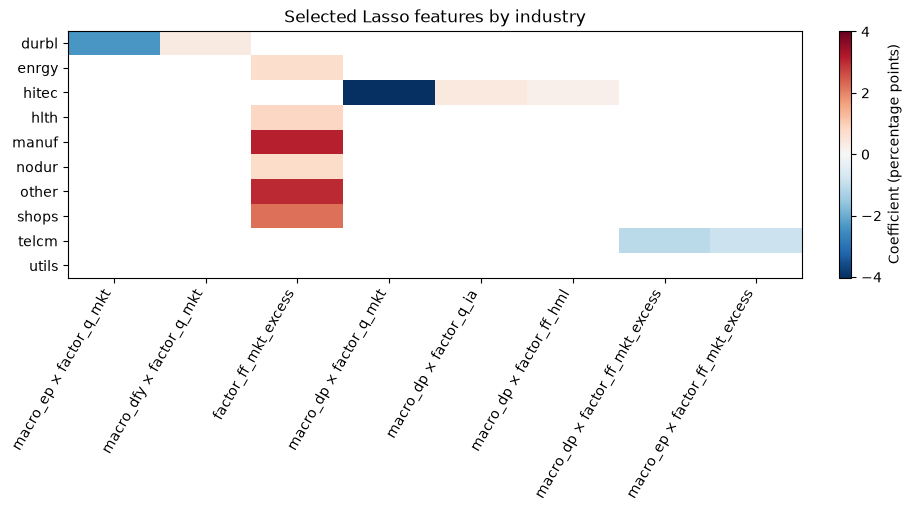

In [5]:
if selected_factors.height:
    shown = selected_factors["变量"].unique(maintain_order=True).to_list()
    matrix = np.full((len(industries), len(shown)), np.nan)
    industry_positions = {name: i for i, name in enumerate(industries)}
    feature_positions = {name: j for j, name in enumerate(shown)}
    for industry, feature, weight, _ in selected_factors.iter_rows():
        matrix[industry_positions[industry], feature_positions[feature]] = weight

    limit = np.nanmax(np.abs(matrix))
    fig, ax = plt.subplots(figsize=(max(9, len(shown) * 0.45), 5), layout="constrained")
    heatmap = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(shown)), shown, rotation=60, ha="right")
    ax.set_yticks(range(len(industries)), industries)
    ax.set_title("Selected Lasso features by industry")
    fig.colorbar(heatmap, ax=ax, label="Coefficient (percentage points)")
    plt.show()

## 5. 解读结果

- **样本外误差。** 测试 RMSE 越低，收益拟合误差越小。样本外 \(R^2\) 以训练期平均收益作为基准。正值表示测试期平方误差低于基准，负值表示高于基准。
- **入选因子。** 系数以百分点报告。正系数表示在其他输入固定时，该候选变量增加一个训练期标准差，模型给出的月度超额收益随之上升。热图空白表示该变量在对应行业的系数为零，完整入选名单见 `selected_factors`。
- **交互项。** 某个“宏观变量 × 因子”入选，表示模型保留了该因子暴露随宏观变量变化的项。相关变量可能在不同训练区间相互替代，入选反映这次拟合下的选择。
- **时间口径。** 收益、因子和宏观变量按同月合并。测试结果衡量模型在较晚月份的同月拟合能力。要评估月初预测，须按实际发布时间重新对齐特征并重跑验证。


## 6. 模型结果评价与对比

本节评价第 4 节结果，基准由训练期平均收益改为仅含市场超额收益的线性回归。新口径 $R^2$ 定义为 1 减去 Lasso 测试均方误差与市场回归测试均方误差之比，正值表示所选变量在纯市场暴露之外降低了测试误差，负值表示其表现不及仅用市场因子。以下三小节分别考察相对市场回归的增量、跨行业的可比口径，以及验证期到测试期的稳定性。

In [6]:
from sklearn.linear_model import LinearRegression

INDUSTRY_NAMES = {
    "nodur": "非耐用消费品",
    "durbl": "耐用消费品",
    "manuf": "制造业",
    "enrgy": "能源",
    "hitec": "高科技",
    "telcm": "电信",
    "shops": "零售",
    "hlth": "医疗",
    "utils": "公用事业",
    "other": "其他",
}

market_rows = []
for industry in industries:
    frame = data.filter(pl.col("industry") == industry).sort("date")
    y = frame["ret_excess"].to_numpy()
    x = frame["factor_ff_mkt_excess"].to_numpy().reshape(-1, 1)
    split = int(len(y) * 0.8)
    fitted = LinearRegression().fit(x[:split], y[:split])
    pred = fitted.predict(x[split:])
    test_mse = mean_squared_error(y[split:], pred)
    market_rows.append({
        "行业": industry,
        "市场测试 RMSE（百分点）": 100 * float(np.sqrt(test_mse)),
    })

comparison = (
    industry_metrics.select(
        "行业",
        "入选数",
        "验证 RMSE（百分点）",
        pl.col("测试 RMSE（百分点）").alias("Lasso 测试 RMSE（百分点）"),
        "基准 RMSE（百分点）",
        pl.col("样本外 R²").alias("旧口径 R²"),
    )
    .join(pl.DataFrame(market_rows), on="行业")
    .with_columns(
        pl.col("行业").replace(INDUSTRY_NAMES).alias("行业名称"),
        (
            1
            - (pl.col("Lasso 测试 RMSE（百分点）") / pl.col("市场测试 RMSE（百分点）")) ** 2
        ).alias("新口径 R²"),
    )
    .with_columns((pl.col("旧口径 R²") - pl.col("新口径 R²")).alias("旧减新"))
    .sort("新口径 R²", descending=True)
)
display(comparison.select(
    "行业", "行业名称", "入选数",
    "Lasso 测试 RMSE（百分点）", "市场测试 RMSE（百分点）",
    "旧口径 R²", "新口径 R²",
))
n_pos = comparison.filter(pl.col("新口径 R²") > 0).height
print(f"新口径 R² 大于 0 的行业有 {n_pos} 个，小于 0 的有 {comparison.height - n_pos} 个。")


行业,行业名称,入选数,Lasso 测试 RMSE（百分点）,市场测试 RMSE（百分点）,旧口径 R²,新口径 R²
str,str,i64,f64,f64,f64,f64
"""hitec""","""高科技""",3,1.668004,2.136886,0.894312,0.3907
"""telcm""","""电信""",2,3.118308,2.777434,0.508893,-0.260522
"""durbl""","""耐用消费品""",2,7.30966,6.25048,0.370282,-0.367627
"""utils""","""公用事业""",0,4.008271,3.366104,0.0,-0.417944
"""enrgy""","""能源""",1,8.011243,6.660429,0.102516,-0.446756
"""nodur""","""非耐用消费品""",1,3.221418,2.436467,0.25355,-0.748127
"""manuf""","""制造业""",1,2.39191,1.722731,0.766463,-0.927767
"""shops""","""零售""",1,2.752309,1.969565,0.629051,-0.952782
"""hlth""","""医疗""",1,3.591854,2.498776,0.270997,-1.066249


新口径 R² 大于 0 的行业有 1 个，小于 0 的有 9 个。


### 6.1 相对市场回归的增量检验

以市场回归为基准，多数行业的稀疏交互项未表现出明显增量。十个行业中仅高科技（0.459）、其他（0.401）和非耐用消费品（0.066）的新口径 $R^2$ 为正，其余七个行业均为负，最低的耐用消费品为 −0.207，能源和零售分别为 −0.197 和 −0.179。负值意味着在这些行业，Lasso 所选变量组合的测试误差高于仅使用市场因子的回归。

旧口径与新口径的差值说明旧口径下的高解释比例在多大程度上来自市场因子。制造和零售的差值最大，分别约为 1.02 和 0.95；制造旧口径 $R^2$ 为 0.859、新口径为 −0.158，零售旧口径为 0.776、新口径为 −0.179，二者的高解释比例主要来自市场暴露，交互项在测试期未继续降低误差。公用事业差值较小，约为 0.31，但其旧口径 $R^2$ 仅为 0.252，市场回归相对常数基准的解释比例本身有限。

### 6.2 跨行业的可比口径

跨行业比较应采用新口径 $R^2$，而非测试 RMSE。耐用消费品基准 RMSE 为 9.31 个百分点、测试 RMSE 为 6.87，公用事业分别为 4.00 和 3.46；前者的原始误差更高源于其波动更大，两者直接比较缺乏统一尺度。按新口径 $R^2$ 划分，高科技和其他两个行业高于 0.3，具有可见增量；非耐用消费品为 0.066，增量有限；其余七个行业为负，从公用事业的 −0.059 到耐用消费品的 −0.207。入选个数与解释能力并不一致：制造、电信和公用事业均保留五个变量，新口径 $R^2$ 均为负；高科技仅保留三个变量，新口径 $R^2$ 最高。

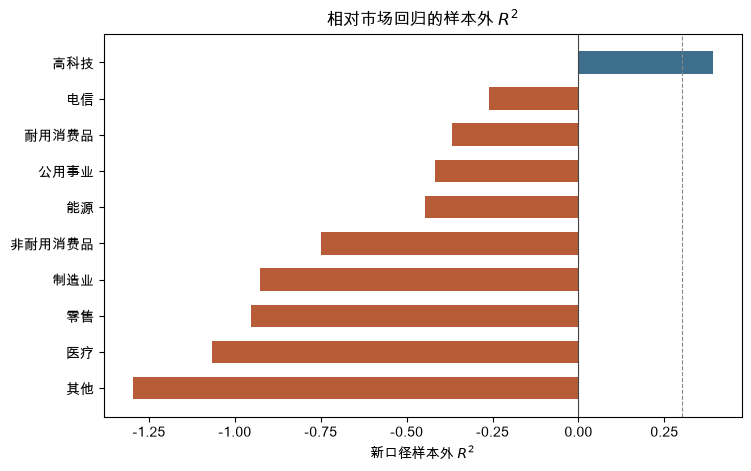

In [7]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

shown = comparison.sort("新口径 R²")
colors = ["#3D6F8C" if value > 0 else "#B85C38" for value in shown["新口径 R²"]]
fig, ax = plt.subplots(figsize=(7.4, 4.6), layout="constrained")
ax.barh(shown["行业名称"].to_list(), shown["新口径 R²"].to_list(), color=colors, height=0.62)
ax.axvline(0, color="#444", linewidth=0.8)
ax.axvline(0.3, color="#888", linewidth=0.8, linestyle="--")
ax.set_xlabel(r"新口径样本外 $R^2$")
ax.set_title(r"相对市场回归的样本外 $R^2$")
plt.show()


### 6.3 验证期到测试期的稳定性

验证期到测试期的表现因行业而异，不宜概括为普遍过拟合。误差上升最明显的是耐用消费品和能源，测试 RMSE 较验证期分别增加 2.86 和 2.69 个百分点；高科技、零售和电信的测试误差则分别下降 2.09、1.04 和 0.90 个百分点。以市场回归的测试 RMSE 为参照，测试期仍低于市场回归的是高科技、其他和非耐用消费品；零售和电信后段误差虽下降，测试误差仍高于市场回归；耐用消费品和能源后段变差，且均不及纯市场回归。


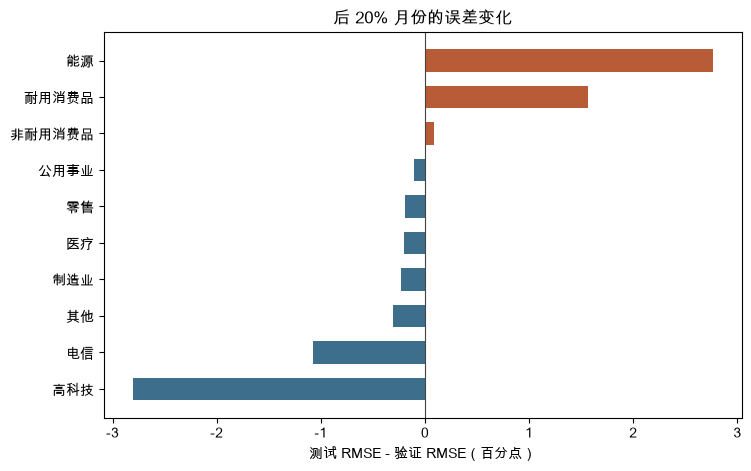

In [8]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

shown = comparison.with_columns(
    (pl.col("Lasso 测试 RMSE（百分点）") - pl.col("验证 RMSE（百分点）")).alias("误差变化")
).sort("误差变化")
colors = ["#B85C38" if value > 0 else "#3D6F8C" for value in shown["误差变化"]]
fig, ax = plt.subplots(figsize=(7.4, 4.6), layout="constrained")
ax.barh(shown["行业名称"].to_list(), shown["误差变化"].to_list(), color=colors, height=0.62)
ax.axvline(0, color="#444", linewidth=0.8)
ax.set_xlabel("测试 RMSE - 验证 RMSE（百分点）")
ax.set_title("后 20% 月份的误差变化")
plt.show()


## 7. 因子筛选的定位与行业差异

本节说明因子筛选结果的定位，并分析行业之间的结构差异。

### 7.1 筛选结果的应用定位与边界

这套筛选的价值在于将 153 个候选变量压缩为一份可读的行业暴露清单，而非解释经济机制或预测下月涨跌。153 个候选经 Lasso 筛选后，每个行业至多保留五个变量，十个行业合计 37 条非零系数；系数以训练期一个标准差对应的月度超额收益百分点表示，热图空白表示该变量在对应行业被压缩为零。该结果是筛选输出，不是结构估计。Lasso 执行的是变量筛选而非因果识别；账面市值比与法玛–弗兰奇市场的交互项和账面市值比与 q 因子市场的交互项经济含义接近，能源保留前者、公用事业保留后者，最终保留哪一项取决于当前训练集与惩罚强度。系数本身既不是因子溢价，也未经过显著性检验。

在此基础上，结果可应用于三类场景。其一，行业风险暴露的精简清单，供归因和风险监控挑选候选变量，但并非完整的风险模型。其二，不同行业暴露结构的对照，用于观察宏观状态下各行业敏感性的差异，但不用于预测涨跌。其三，降维，将 153 维候选压缩至每个行业五个以内，作为后续模型的输入候选，但不能替代后续模型。受同月合并、行业组合、非因子溢价和非择时信号等口径限制，这套结果适用于结构刻画、归因与降维。

### 7.2 行业覆盖能力的结构差异

筛选结果反映的是候选变量对各行业覆盖能力的差异，而非行业模型之间的优劣排序。按新口径 $R^2$ 分组，高科技和其他具有可见增量，非耐用消费品增量有限，其余七个行业不及纯市场回归；同为负值，公用事业仅低 0.059，耐用消费品低 0.207，覆盖不足的程度并不相同。入选个数与覆盖能力不成正比：制造、电信和公用事业均保留五个变量而新口径 $R^2$ 为负，高科技仅保留三个变量而新口径 $R^2$ 最高。

低于市场回归的行业，原因并不相同。耐用消费品为后段不稳，表上仅保留两项对 q 因子市场的调节，盈利收益率与 q 因子市场的交互项约为 −2.87，违约利差与 q 因子市场的交互项约为 +0.90，无裸市场因子，验证 RMSE 由 4.01 升至 6.87，新口径 $R^2$ 为 −0.207。能源保留了裸 q 因子市场（约 +1.70）和账面市值比与法玛–弗兰奇市场的交互项（约 +0.74），验证 RMSE 由 4.60 升至 7.29，新口径 $R^2$ 为 −0.197，市场项存在但后段未能承接。公用事业保留五个变量，涵盖 q 因子市场、账面市值比与 q 因子市场的交互项、长期债券收益、违约利差与 q 因子市场的交互项以及接近零的分红比率与价值因子的交互项，新口径 $R^2$ 为 −0.059，变量数量达到上限并未转化为对市场残差的解释。

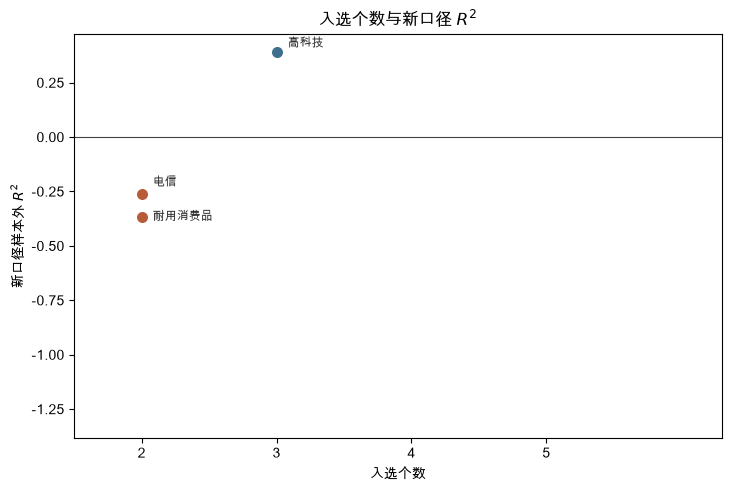

In [9]:
from matplotlib import font_manager

for font in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei"]:
    if any(found.name == font for found in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        break

offsets = {
    "耐用消费品": (8, -2),
    "能源": (8, -2),
    "零售": (8, 6),
    "制造业": (8, -8),
    "电信": (8, 6),
    "医疗": (-36, 8),
    "公用事业": (8, 8),
    "非耐用消费品": (8, -10),
    "其他": (8, 4),
    "高科技": (8, 4),
}
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
for name, count, r2 in comparison.select("行业名称", "入选数", "新口径 R²").iter_rows():
    ax.scatter(count, r2, s=48, color="#3D6F8C" if r2 > 0 else "#B85C38", zorder=3)
    ax.annotate(name, (count, r2), textcoords="offset points", xytext=offsets.get(name, (8, 4)), fontsize=8.5, color="#333")
ax.axhline(0, color="#444", linewidth=0.8)
ax.set_xticks([2, 3, 4, 5])
ax.set_xlim(1.5, 6.3)
ax.set_xlabel("入选个数")
ax.set_ylabel(r"新口径样本外 $R^2$")
ax.set_title(r"入选个数与新口径 $R^2$")
plt.show()
